# Динамика конечного захода – протокол исследования

**Версия 1.1 · 12 октября 2026 · этап 00**

Исследовательский вопрос: можно ли по уже доступной динамике конечного захода предсказать выход за обоснованные границы профиля до контрольной высоты и дать интерпретируемую оценку риска?

Объект первого этапа – LFPG; следующий аэропорт – EGLL. Здесь фиксируются постановка и исходные агрегаты. Пригодность траекторий еще не установлена. Обучение и прогноз отдельных заходов на этом этапе не выполняются.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
# Определяем папку аэропорта независимо от запуска из notebooks
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
PROJECT = ROOT.parents[1]
assert (PROJECT / 'configs/sources.json').is_file()
for name in ['reports', 'figures']:
    (ROOT / name).mkdir(exist_ok=True)
# Сохраняем палитру первой версии для сопоставимости рисунков
RED = '#D65A4A'  # Красный: коралловый цвет
GREEN = '#00897B'
plt.rcParams.update({'axes.prop_cycle': plt.cycler(color=[RED, GREEN]),
                     'figure.dpi': 130, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
# Читаем сохраненную сводку без изменения исходных данных
config = json.loads((PROJECT / 'configs/sources.json').read_text(encoding='utf-8'))
source = (PROJECT / config['airport_summary']).resolve()
summary = pd.read_csv(source)
# Порядок строк соответствует последовательности исследования аэропортов
selected = summary.set_index('airport').loc[['LFPG', 'EGLL']].reset_index()
selected.to_csv(ROOT / 'reports/00_airport_summary.csv', index=False)
# Хеш фиксирует точную версию исходника для воспроизведения
provenance = {'source': config['airport_summary'],
              'sha256': hashlib.sha256(source.read_bytes()).hexdigest(),
              'role': config['source_role'], 'python': platform.python_version(),
              'pandas': pd.__version__, 'matplotlib': matplotlib.__version__}
(ROOT / 'reports/00_provenance.json').write_text(
    json.dumps(provenance, ensure_ascii=False, indent=2), encoding='utf-8')
display(selected.rename(columns={'airport': 'Аэропорт', 'rows': 'Записи',
    'go_arounds': 'Метки GoA', 'ga_percent': 'GoA, %'}))

,Аэропорт,country,city,Записи,Метки GoA,"GoA, %"
0,LFPG,France,Париж,701670,2653,0.378098
1,EGLL,United Kingdom,Лондон,686819,2607,0.379576


## Объем исходной таблицы

Сводка перенесена из сохраненного отчета версии 1.0 с фиксацией хеша. Это агрегаты строк и меток источника, а не независимо подтвержденные уходы и не число полных траекторий. График показывает запас исходных записей для последующего отбора; он не измеряет качество данных.

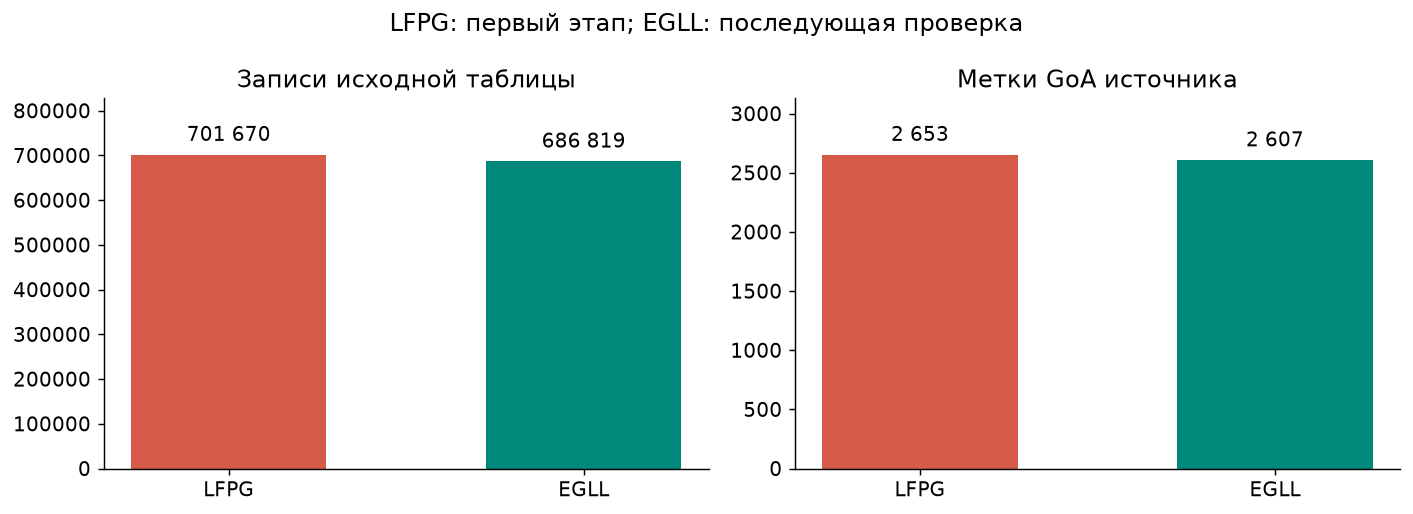

In [2]:
# Показываем объем записей и меток отдельно от качества траекторий
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, field, title in zip(axes, ['rows', 'go_arounds'],
                           ['Записи исходной таблицы', 'Метки GoA источника']):
    values = selected[field].tolist()
    bars = ax.bar(selected['airport'], values, color=[RED, GREEN], width=0.55)
    ax.bar_label(bars, labels=[f'{v:,}'.replace(',', ' ') for v in values], padding=5)
    ax.set_title(title)
    ax.set_ylim(0, max(values) * 1.18)
    ax.ticklabel_format(axis='y', style='plain')
fig.suptitle('LFPG: первый этап; EGLL: последующая проверка')
fig.tight_layout()
# Сохраняем растровую и векторную версии для отчетов
fig.savefig(ROOT / 'figures/00_airport_volume.png', bbox_inches='tight')
fig.savefig(ROOT / 'figures/00_airport_volume.svg', bbox_inches='tight')
plt.show()

## Постановка и границы метода

| Компонент | Принято | Требует исследования |
|---|---|---|
| География | LFPG, затем EGLL | Одно направление ВПП для первого этапа |
| Начало | Захват глиссады или обозначенный прокси | Наблюдаемость и критерий начала |
| Конец | 300 ft над аэродромом | Высотная система и чувствительность к границе |
| Baseline | Постоянные скорость, вертикальная скорость, направление | Горизонт прогноза и неопределенность |
| Информация | Только доступная к моменту прогноза | Задержки и порядок поступления |
| Результаты | Нарушение профиля и фактический GoA отдельно | Разметка, временная точность, качество меток |
| Оценка | Время до границы и события отклонения | Допуски, длительность, объединение событий |

Пять минут не являются фиксированным окном от будущей посадки. Двусторонняя интерполяция не используется для получения доступных в прошлом признаков. Успешная посадка не определяет допустимость отклонения.

Предварительные баллы 0,5 / 1 / 1,5 / 2 и порог 2 остаются гипотезами. Для одного развивающегося события балл обновляется, а не суммируется при каждом наблюдении. Причинные объяснения требуют отдельного обоснования.

## Протокол проверки пригодности данных

До выбора ВПП необходимо проверить следующие свойства. Отсутствие сведений обозначается как неизвестность, а не как положительный результат.

In [3]:
# Фиксируем критерии до анализа траекторий и выбора направления ВПП
criteria = pd.DataFrame([
    ['Траектории', 'Есть временные ряды конечного участка посадок и уходов'],
    ['ВПП', 'Направление определено с оценкой неоднозначных случаев'],
    ['Время', 'Определены UTC, частота, пропуски и порядок наблюдений'],
    ['Высота', 'Различены барометрическая, геометрическая и высота над аэродромом'],
    ['Процедура', 'Есть геометрия и документы, действовавшие на даты полетов'],
    ['Метки', 'Проверены попытки захода, дубликаты и время начала ухода'],
    ['Доступность', 'Оценены задержки; будущие точки не входят в признаки'],
    ['Отбор', 'Описаны потери посадок и GoA по каждому критерию'],
], columns=['Область', 'Проверка'])
# Наличие агрегатов не подтверждает выполнение критериев пригодности
criteria['Статус'] = 'Не проверено'
criteria.to_csv(ROOT / 'reports/00_data_readiness.csv', index=False)
display(criteria)

,Область,Проверка,Статус
0,Траектории,Есть временные ряды конечного участка посадок ...,Не проверено
1,ВПП,Направление определено с оценкой неоднозначных...,Не проверено
2,Время,"Определены UTC, частота, пропуски и порядок на...",Не проверено
3,Высота,"Различены барометрическая, геометрическая и вы...",Не проверено
4,Процедура,"Есть геометрия и документы, действовавшие на д...",Не проверено
5,Метки,"Проверены попытки захода, дубликаты и время на...",Не проверено
6,Доступность,Оценены задержки; будущие точки не входят в пр...,Не проверено
7,Отбор,Описаны потери посадок и GoA по каждому критерию,Не проверено


## План оценки

1. Провести инвентаризацию доступных источников LFPG и небольшой пилот конечных участков. Выбрать направление ВПП по полноте посадок и уходов, а не по результатам модели.
2. Определить единицу наблюдения как попытку захода. Учитывать составной ключ и повторные попытки; flight_id сам по себе недостаточен.
3. Разделить периоды разработки, калибровки и проверки. Повторные попытки одного полета не должны попадать в разные части выборки.
4. Проиграть траектории последовательно во времени. Оценить ошибки прогноза профиля, время предупреждения, ложные предупреждения на заход и пропущенные события. Для GoA отдельно представить precision, recall и зависимость от порога.
5. Оценить неопределенность с учетом зависимости наблюдений внутри заходов и временных блоков. После фиксации метода проверить EGLL и отдельно описать различия покрытия и процедур.

## Результат этапа 00

Зафиксированы последовательность аэропортов, границы baseline и критерии проверки источников. Агрегаты подтверждают наличие записей LFPG и EGLL в прежней таблице. Они не подтверждают наличие пригодного конечного участка. Следующий результат исследования – отчет о доступности и качестве траекторий LFPG.